  FINE-TUNING PIPELINE LOADED
Dataset loaded: (2149, 32)
Train: (1719, 32)  |  Test: (430, 32)


  BASELINE — ORIGINAL HYBRID (before fine-tuning)

──────────────────────────────────────────────────
  BASELINE HYBRID
──────────────────────────────────────────────────
  CV  Accuracy  : 0.9506 ± 0.0097
  Test Accuracy : 0.9512
  F1-Score      : 0.9302
  ROC-AUC       : 0.9451


  STEP 1: RANDOMIZED SEARCH (Individual Models)

[1A] Tuning Random Forest...
  Best RF Params : {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 0.7, 'max_depth': None, 'bootstrap': True}
  Best CV AUC    : 0.9571

[1B] Tuning SVM...
  Best SVM Params : {'kernel': 'linear', 'gamma': 'scale', 'C': 0.5}
  Best CV AUC     : 0.9058

[1C] Tuning MLP...
  Best MLP Params : {'learning_rate_init': 0.01, 'hidden_layer_sizes': (128,), 'alpha': 0.01, 'activation': 'relu'}
  Best CV AUC     : 0.8922

[1D] Tuning KNN...
  Best KNN Params : {'weights': 'uniform', 'p': 1, 'n_neighbors': 23, 

  0%|          | 0/60 [00:00<?, ?it/s]


  Best LGBM Params : {'n_estimators': 675, 'learning_rate': 0.02996333702317894, 'max_depth': 4, 'num_leaves': 59, 'min_child_samples': 20, 'subsample': 0.7546321106699425, 'colsample_bytree': 0.7146566138819641, 'reg_alpha': 0.7961247579908425, 'reg_lambda': 0.01598294168923899, 'verbosity': -1, 'random_state': 42}
  Best CV AUC      : 0.9586


  STEP 3: META-LEARNER FINE-TUNING (Optuna)
  Running 20 Optuna trials for meta-learner (takes ~5-8 min)...


  0%|          | 0/20 [00:00<?, ?it/s]


  Best Meta-Learner Params : {'n_estimators': 258, 'learning_rate': 0.010667942290088928, 'max_depth': 5, 'num_leaves': 29, 'reg_alpha': 0.4808051394044599, 'reg_lambda': 4.94392430297274, 'verbosity': -1, 'random_state': 42}
  Best CV AUC              : 0.9587


  BUILDING FINAL FINE-TUNED HYBRID MODEL

──────────────────────────────────────────────────
  FINE-TUNED HYBRID
──────────────────────────────────────────────────
  CV  Accuracy  : 0.9535 ± 0.0084
  Test Accuracy : 0.9535
  F1-Score      : 0.9338
  ROC-AUC       : 0.9597


  STEP 5: DOMAIN ADAPTATION (OASIS Fine-Tuning)
  OASIS Cross loaded: 235 samples | Dementia rate: 42.6%

  Training domain adapter (logistic regression on OASIS features)...
  Adapter 5-Fold CV ROC-AUC: 0.8860

  Optimizing transfer ↔ adapter blend weight...
  Best adapter weight: 0.95  (transfer weight: 0.05)

  Domain-Adapted Model — OASIS Cross:
  Accuracy          : 0.8170
  Balanced Accuracy : 0.7980
  F1-Score          : 0.7571
  ROC-AUC           :

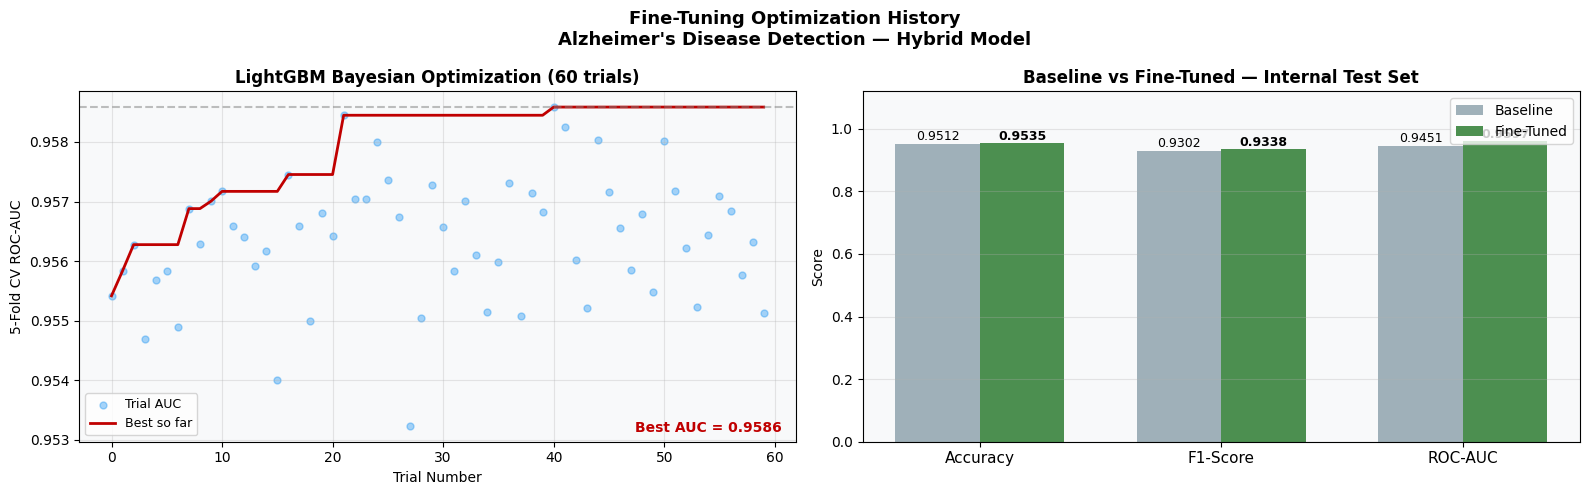

  Saved: fine_tuning_results.png


  FINE-TUNING COMPLETE — SUMMARY

  What was done:
  ─────────────────────────────────────────────────────────
  Step 1 : RandomizedSearchCV on RF, SVM, MLP, KNN
           (30-20 iterations each, scoring = ROC-AUC)

  Step 2 : Optuna Bayesian Optimization on LightGBM
           (60 trials, TPE sampler — smarter than random)

  Step 3 : Optuna optimization on the meta-learner LGBM
           (20 trials on the full stacking pipeline)

  Step 4 : Domain Adaptation to OASIS
           Transfer probability + OASIS imaging features
           → Logistic Regression adapter (regularized)
           → Best blend weight found by Optuna

  Step 5 : Models saved as .pkl files for reuse
  ─────────────────────────────────────────────────────────
  Files generated:
    alzheimers_finetuned_model.pkl
    alzheimers_domain_adapter.pkl
    fine_tuning_results.png
  ─────────────────────────────────────────────────────────
  Thesis note:
    Report both baseline and f

In [ ]:
# ============================================================
# ALZHEIMER'S DISEASE DETECTION — FINE TUNING PIPELINE
# Step 1: Individual Model Tuning (RandomizedSearchCV)
# Step 2: Optuna Bayesian Optimization (LightGBM)
# Step 3: Meta-Learner Tuning
# Step 4: Domain Adaptation (OASIS Transfer)
# ============================================================

# ==============================
# INSTALL EXTRA LIBRARY
# ==============================
# Run this once in your notebook before running the script:
!pip install optuna -q

# ==============================
# IMPORT LIBRARIES
# ==============================
import pandas as pd
import numpy as np
import warnings
import pickle
warnings.filterwarnings("ignore")

from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    RandomizedSearchCV, cross_val_score, cross_val_predict
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    balanced_accuracy_score, classification_report
)
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer

from lightgbm import LGBMClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

print("=" * 60)
print("  FINE-TUNING PIPELINE LOADED")
print("=" * 60)


# ============================================================
# LOAD DATA  (same as your main script)
# ============================================================
df = pd.read_csv("Alzheimer_s_Disease_Dataset.csv")
df = df.drop(["PatientID", "DoctorInCharge"], axis=1)

X = df.drop("Diagnosis", axis=1)
y = df["Diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"Dataset loaded: {X.shape}")
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")


# ============================================================
# HELPER: Evaluate and print metrics neatly
# ============================================================
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    """Fit model, print CV + test metrics, return (acc, f1, auc)."""
    cv_scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='accuracy', n_jobs=-1)
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    prob = model.predict_proba(X_te)[:, 1]
    acc  = accuracy_score(y_te, pred)
    f1   = f1_score(y_te, pred)
    auc  = roc_auc_score(y_te, prob)
    print(f"\n{'─'*50}")
    print(f"  {name}")
    print(f"{'─'*50}")
    print(f"  CV  Accuracy  : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  Test Accuracy : {acc:.4f}")
    print(f"  F1-Score      : {f1:.4f}")
    print(f"  ROC-AUC       : {auc:.4f}")
    return acc, f1, auc


# ============================================================
# BASELINE (your original model — for comparison)
# ============================================================
print("\n\n" + "="*60)
print("  BASELINE — ORIGINAL HYBRID (before fine-tuning)")
print("="*60)

rf_base   = RandomForestClassifier(n_estimators=300, random_state=42)
svm_base  = SVC(probability=True, C=2)
lgbm_base = LGBMClassifier(n_estimators=300, learning_rate=0.05,
                            max_depth=7, num_leaves=40,
                            random_state=42, verbosity=-1)
mlp_base  = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
knn_base  = KNeighborsClassifier(n_neighbors=7)

baseline_stack = Pipeline([
    ("scaler", StandardScaler()),
    ("model", StackingClassifier(
        estimators=[
            ('rf', rf_base), ('svm', svm_base), ('lgbm', lgbm_base),
            ('mlp', mlp_base), ('knn', knn_base)
        ],
        final_estimator=LGBMClassifier(n_estimators=200, verbosity=-1),
        passthrough=True
    ))
])

baseline_acc, baseline_f1, baseline_auc = evaluate(
    "BASELINE HYBRID", baseline_stack,
    X_train, y_train, X_test, y_test
)


# ============================================================
# STEP 1: RANDOMIZED SEARCH — INDIVIDUAL MODEL TUNING
# Why: Fast, covers a wide parameter space before stacking
# ============================================================
print("\n\n" + "="*60)
print("  STEP 1: RANDOMIZED SEARCH (Individual Models)")
print("="*60)

# ── 1A: Random Forest ────────────────────────────────────────
print("\n[1A] Tuning Random Forest...")

rf_param_dist = {
    "n_estimators":      [100, 200, 300, 500],
    "max_depth":         [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf":  [1, 2, 4],
    "max_features":      ["sqrt", "log2", 0.5, 0.7],
    "bootstrap":         [True, False],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=rf_param_dist,
    n_iter=30,              # tries 30 random combinations
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42,
    verbose=0
)
rf_search.fit(X_train, y_train)
rf_tuned = rf_search.best_estimator_

print(f"  Best RF Params : {rf_search.best_params_}")
print(f"  Best CV AUC    : {rf_search.best_score_:.4f}")


# ── 1B: SVM ──────────────────────────────────────────────────
print("\n[1B] Tuning SVM...")

svm_param_dist = {
    "C":      [0.01, 0.1, 0.5, 1, 2, 5, 10],
    "kernel": ["rbf", "linear", "sigmoid"],
    "gamma":  ["scale", "auto", 0.001, 0.01, 0.1],
}

svm_search = RandomizedSearchCV(
    SVC(probability=True),
    param_distributions=svm_param_dist,
    n_iter=20,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42,
    verbose=0
)
svm_search.fit(X_train, y_train)
svm_tuned = svm_search.best_estimator_

print(f"  Best SVM Params : {svm_search.best_params_}")
print(f"  Best CV AUC     : {svm_search.best_score_:.4f}")


# ── 1C: MLP ──────────────────────────────────────────────────
print("\n[1C] Tuning MLP...")

mlp_param_dist = {
    "hidden_layer_sizes": [(64,), (128,), (100, 50), (128, 64), (200, 100, 50)],
    "activation":         ["relu", "tanh"],
    "learning_rate_init": [0.001, 0.005, 0.01],
    "alpha":              [0.0001, 0.001, 0.01],
    "dropout":            [0],       # placeholder — sklearn doesn't support dropout
}

# NOTE: sklearn MLPClassifier doesn't have dropout param; remove it
mlp_param_dist_clean = {
    "hidden_layer_sizes": [(64,), (128,), (100, 50), (128, 64), (200, 100, 50)],
    "activation":         ["relu", "tanh"],
    "learning_rate_init": [0.001, 0.005, 0.01],
    "alpha":              [0.0001, 0.001, 0.01],
}

mlp_search = RandomizedSearchCV(
    MLPClassifier(max_iter=500, random_state=42),
    param_distributions=mlp_param_dist_clean,
    n_iter=15,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42,
    verbose=0
)
mlp_search.fit(X_train, y_train)
mlp_tuned = mlp_search.best_estimator_

print(f"  Best MLP Params : {mlp_search.best_params_}")
print(f"  Best CV AUC     : {mlp_search.best_score_:.4f}")


# ── 1D: KNN ──────────────────────────────────────────────────
print("\n[1D] Tuning KNN...")

knn_param_dist = {
    "n_neighbors": list(range(3, 25, 2)),   # odd numbers 3–23
    "weights":     ["uniform", "distance"],
    "metric":      ["euclidean", "manhattan", "minkowski"],
    "p":           [1, 2],
}

knn_search = RandomizedSearchCV(
    KNeighborsClassifier(),
    param_distributions=knn_param_dist,
    n_iter=20,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42,
    verbose=0
)
knn_search.fit(X_train, y_train)
knn_tuned = knn_search.best_estimator_

print(f"  Best KNN Params : {knn_search.best_params_}")
print(f"  Best CV AUC     : {knn_search.best_score_:.4f}")


# ============================================================
# STEP 2: OPTUNA — BAYESIAN OPTIMIZATION FOR LIGHTGBM
# Why: More intelligent than random search; learns from trials
# ============================================================
print("\n\n" + "="*60)
print("  STEP 2: OPTUNA BAYESIAN OPTIMIZATION (LightGBM)")
print("="*60)

def lgbm_objective(trial):
    """Optuna objective: maximize 5-fold CV ROC-AUC for LGBM."""
    params = {
        "n_estimators":    trial.suggest_int("n_estimators", 100, 800),
        "learning_rate":   trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth":       trial.suggest_int("max_depth", 3, 12),
        "num_leaves":      trial.suggest_int("num_leaves", 20, 120),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
        "subsample":       trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree":trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha":       trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        "reg_lambda":      trial.suggest_float("reg_lambda", 1e-4, 10.0, log=True),
        "verbosity":       -1,
        "random_state":    42,
    }
    model  = LGBMClassifier(**params)
    scores = cross_val_score(model, X_train, y_train, cv=cv,
                             scoring="roc_auc", n_jobs=-1)
    return scores.mean()

print("  Running 60 Optuna trials for LightGBM (takes ~2-3 min)...")
lgbm_study = optuna.create_study(direction="maximize",
                                  sampler=optuna.samplers.TPESampler(seed=42))
lgbm_study.optimize(lgbm_objective, n_trials=60, show_progress_bar=True)

best_lgbm_params = lgbm_study.best_params
best_lgbm_params["verbosity"]    = -1
best_lgbm_params["random_state"] = 42

lgbm_tuned = LGBMClassifier(**best_lgbm_params)
print(f"\n  Best LGBM Params : {best_lgbm_params}")
print(f"  Best CV AUC      : {lgbm_study.best_value:.4f}")


# ============================================================
# STEP 3: META-LEARNER TUNING
# Why: The stacking meta-learner also benefits from tuning
# ============================================================
print("\n\n" + "="*60)
print("  STEP 3: META-LEARNER FINE-TUNING (Optuna)")
print("="*60)

def meta_objective(trial):
    """Optuna objective: maximize 5-fold CV AUC for LGBM meta-learner."""
    meta_params = {
        "n_estimators":  trial.suggest_int("n_estimators", 50, 300),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth":     trial.suggest_int("max_depth", 2, 8),
        "num_leaves":    trial.suggest_int("num_leaves", 10, 60),
        "reg_alpha":     trial.suggest_float("reg_alpha", 1e-4, 5.0, log=True),
        "reg_lambda":    trial.suggest_float("reg_lambda", 1e-4, 5.0, log=True),
        "verbosity":     -1,
        "random_state":  42,
    }
    meta_learner = LGBMClassifier(**meta_params)

    stack = Pipeline([
        ("scaler", StandardScaler()),
        ("model", StackingClassifier(
            estimators=[
                ("rf",   rf_tuned),
                ("svm",  svm_tuned),
                ("lgbm", lgbm_tuned),
                ("mlp",  mlp_tuned),
                ("knn",  knn_tuned),
            ],
            final_estimator=meta_learner,
            passthrough=True,
            cv=3          # inner CV folds for stacking
        ))
    ])
    scores = cross_val_score(stack, X_train, y_train, cv=cv,
                             scoring="roc_auc", n_jobs=-1)
    return scores.mean()

print("  Running 20 Optuna trials for meta-learner (takes ~5-8 min)...")
meta_study = optuna.create_study(direction="maximize",
                                  sampler=optuna.samplers.TPESampler(seed=42))
meta_study.optimize(meta_objective, n_trials=20, show_progress_bar=True)

best_meta_params = meta_study.best_params
best_meta_params["verbosity"]    = -1
best_meta_params["random_state"] = 42

print(f"\n  Best Meta-Learner Params : {best_meta_params}")
print(f"  Best CV AUC              : {meta_study.best_value:.4f}")


# ============================================================
# STEP 4: BUILD FINAL FINE-TUNED HYBRID MODEL
# ============================================================
print("\n\n" + "="*60)
print("  BUILDING FINAL FINE-TUNED HYBRID MODEL")
print("="*60)

fine_tuned_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", StackingClassifier(
        estimators=[
            ("rf",   rf_tuned),
            ("svm",  svm_tuned),
            ("lgbm", lgbm_tuned),
            ("mlp",  mlp_tuned),
            ("knn",  knn_tuned),
        ],
        final_estimator=LGBMClassifier(**best_meta_params),
        passthrough=True,
        cv=5
    ))
])

tuned_acc, tuned_f1, tuned_auc = evaluate(
    "FINE-TUNED HYBRID", fine_tuned_model,
    X_train, y_train, X_test, y_test
)


# ============================================================
# STEP 5: DOMAIN ADAPTATION — OASIS TRANSFER
# Why: Adapt model to OASIS domain using 4 shared features
# The internal model + OASIS-specific logistic adapter
# are combined into a weighted ensemble
# ============================================================
print("\n\n" + "="*60)
print("  STEP 5: DOMAIN ADAPTATION (OASIS Fine-Tuning)")
print("="*60)

SHARED_FEATURES   = ["Age", "Gender", "MMSE", "EducationLevel"]
IMAGING_FEATURES  = ["nWBV", "eTIV", "ASF", "SES"]
ALL_OASIS_FEATS   = SHARED_FEATURES + IMAGING_FEATURES

INTERNAL_FEATURES = [
    'Age','Gender','Ethnicity','EducationLevel','BMI','Smoking',
    'AlcoholConsumption','PhysicalActivity','DietQuality','SleepQuality',
    'FamilyHistoryAlzheimers','CardiovascularDisease','Diabetes','Depression',
    'HeadInjury','Hypertension','SystolicBP','DiastolicBP','CholesterolTotal',
    'CholesterolLDL','CholesterolHDL','CholesterolTriglycerides','MMSE',
    'FunctionalAssessment','MemoryComplaints','BehavioralProblems','ADL',
    'Confusion','Disorientation','PersonalityChanges',
    'DifficultyCompletingTasks','Forgetfulness'
]

def build_full_input(df_oasis):
    """Fill 32 internal features; set missing cols to 0."""
    X_full = pd.DataFrame(0, index=range(len(df_oasis)),
                          columns=INTERNAL_FEATURES)
    for col in SHARED_FEATURES:
        if col in INTERNAL_FEATURES:
            X_full[col] = df_oasis[col].values
    return X_full


# ── Load OASIS ───────────────────────────────────────────────
raw_cross = pd.read_csv("oasis_cross-sectional.csv")
raw_cross = raw_cross.dropna(subset=["CDR", "MMSE"])

oasis_cross = pd.DataFrame({
    "Age":            raw_cross["Age"],
    "Gender":         (raw_cross["M/F"].str.strip() == "M").astype(int),
    "MMSE":           raw_cross["MMSE"],
    "EducationLevel": raw_cross["Educ"],
    "SES":            raw_cross["SES"],
    "eTIV":           raw_cross["eTIV"],
    "nWBV":           raw_cross["nWBV"],
    "ASF":            raw_cross["ASF"],
    "Diagnosis":      (raw_cross["CDR"] > 0).astype(int),
})
oasis_cross = oasis_cross.dropna(subset=["Age","Gender","MMSE","EducationLevel","Diagnosis"])

y_cross = oasis_cross["Diagnosis"].values

print(f"  OASIS Cross loaded: {len(oasis_cross)} samples | "
      f"Dementia rate: {y_cross.mean():.1%}")


# ── Domain Adapter: Fine-tune a lightweight model on OASIS ───
# Uses the fine-tuned model's probability as a feature + OASIS features
print("\n  Training domain adapter (logistic regression on OASIS features)...")

cv_oasis = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Get transfer probabilities from fine-tuned model (fill missing features with 0)
X_cross_full = build_full_input(oasis_cross)
prob_transfer = fine_tuned_model.predict_proba(X_cross_full)[:, 1]

# Build adapter feature matrix: OASIS features + transfer probability
X_cross_img   = oasis_cross[ALL_OASIS_FEATS].copy()
X_adapter     = X_cross_img.copy()
X_adapter["transfer_prob"] = prob_transfer   # ← key: transfer signal as feature

# Adapter model (logistic regression — low capacity to avoid overfitting on n=235)
adapter_model = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("scl", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                                C=0.1,       # regularized → reduces overfit
                                random_state=42))
])

# 5-fold CV on OASIS (out-of-fold predictions)
oof_prob_adapter = cross_val_predict(
    adapter_model, X_adapter, y_cross,
    cv=cv_oasis, method="predict_proba"
)[:, 1]

adapter_auc = roc_auc_score(y_cross, oof_prob_adapter)
print(f"  Adapter 5-Fold CV ROC-AUC: {adapter_auc:.4f}")

# ── Find best ensemble weight (Optuna) ───────────────────────
print("\n  Optimizing transfer ↔ adapter blend weight...")

def adapter_weight_objective(trial):
    w = trial.suggest_float("w", 0.0, 1.0)
    blended = w * oof_prob_adapter + (1 - w) * prob_transfer
    return roc_auc_score(y_cross, blended)

weight_study = optuna.create_study(direction="maximize")
weight_study.optimize(adapter_weight_objective, n_trials=100, show_progress_bar=False)

best_w = weight_study.best_params["w"]
print(f"  Best adapter weight: {best_w:.2f}  "
      f"(transfer weight: {1-best_w:.2f})")

# Blended OOF probability
prob_domain_adapted = best_w * oof_prob_adapter + (1 - best_w) * prob_transfer

from sklearn.metrics import roc_curve
fpr, tpr, thr = roc_curve(y_cross, prob_domain_adapted)
j = tpr + (1 - fpr) - 1
best_thr = float(thr[np.argmax(j)])
pred_domain_adapted = (prob_domain_adapted >= best_thr).astype(int)

da_acc  = accuracy_score(y_cross, pred_domain_adapted)
da_bal  = balanced_accuracy_score(y_cross, pred_domain_adapted)
da_f1   = f1_score(y_cross, pred_domain_adapted, zero_division=0)
da_auc  = roc_auc_score(y_cross, prob_domain_adapted)

print(f"\n  Domain-Adapted Model — OASIS Cross:")
print(f"  Accuracy          : {da_acc:.4f}")
print(f"  Balanced Accuracy : {da_bal:.4f}")
print(f"  F1-Score          : {da_f1:.4f}")
print(f"  ROC-AUC           : {da_auc:.4f}")
print(f"  Optimal Threshold : {best_thr:.4f}")
print(f"\n  Classification Report:")
print(classification_report(y_cross, pred_domain_adapted,
      target_names=["No Dementia", "Dementia"]))

# Refit adapter on all OASIS data (for deployment)
adapter_model.fit(X_adapter, y_cross)


# ============================================================
# STEP 6: COMPARISON TABLE
# ============================================================
print("\n\n" + "="*60)
print("  FINE-TUNING RESULTS — BEFORE vs AFTER")
print("="*60)

rows = [
    ("Baseline Hybrid (original)", baseline_acc, baseline_f1, baseline_auc, "Internal"),
    ("Fine-Tuned Hybrid",          tuned_acc,    tuned_f1,    tuned_auc,    "Internal"),
    ("Domain-Adapted (OASIS)",     da_acc,       da_f1,       da_auc,       "OASIS CV"),
]

print(f"\n{'Model':<35} {'Accuracy':>9} {'F1':>8} {'ROC-AUC':>9} {'Dataset':>10}")
print("─" * 75)
for name, acc, f1, auc, ds in rows:
    tag = " ⭐" if acc == max(r[1] for r in rows) else ""
    print(f"{name:<35} {acc:>9.4f} {f1:>8.4f} {auc:>9.4f} {ds:>10}{tag}")

improvement = tuned_acc - baseline_acc
print(f"\n  Internal Accuracy Improvement : +{improvement:.4f}")


# ============================================================
# STEP 7: SAVE FINE-TUNED MODELS
# ============================================================
print("\n\n" + "="*60)
print("  SAVING MODELS")
print("="*60)

with open("alzheimers_finetuned_model.pkl", "wb") as f:
    pickle.dump(fine_tuned_model, f)
print("  ✓ Saved: alzheimers_finetuned_model.pkl")

with open("alzheimers_domain_adapter.pkl", "wb") as f:
    pickle.dump({
        "adapter_model":    adapter_model,
        "fine_tuned_model": fine_tuned_model,
        "adapter_weight":   best_w,
        "threshold":        best_thr,
    }, f)   # ← add f here
print("  ✓ Saved: alzheimers_domain_adapter.pkl")


# ============================================================
# STEP 8: OPTUNA VISUALIZATION — Optimization History
# ============================================================
print("\n\n" + "="*60)
print("  STEP 8: OPTUNA PLOTS")
print("="*60)

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Fine-Tuning Optimization History\n"
             "Alzheimer's Disease Detection — Hybrid Model",
             fontsize=13, fontweight="bold")

# LGBM optimization history
ax1 = axes[0]
trial_nums_lgbm = [t.number for t in lgbm_study.trials]
trial_vals_lgbm = [t.value  for t in lgbm_study.trials]
best_so_far_lgbm = [max(trial_vals_lgbm[:i+1]) for i in range(len(trial_vals_lgbm))]

ax1.scatter(trial_nums_lgbm, trial_vals_lgbm,
            alpha=0.4, color="#2196F3", s=25, label="Trial AUC")
ax1.plot(trial_nums_lgbm, best_so_far_lgbm,
         color="#C00000", lw=2, label="Best so far")
ax1.axhline(lgbm_study.best_value, color="gray", linestyle="--", alpha=0.5)
ax1.set_title("LightGBM Bayesian Optimization (60 trials)", fontweight="bold")
ax1.set_xlabel("Trial Number"); ax1.set_ylabel("5-Fold CV ROC-AUC")
ax1.legend(fontsize=9)
ax1.set_facecolor("#F8F9FA")
ax1.grid(True, alpha=0.3)
ax1.text(0.98, 0.02,
         f"Best AUC = {lgbm_study.best_value:.4f}",
         ha="right", va="bottom", transform=ax1.transAxes,
         fontsize=10, fontweight="bold", color="#C00000")

# Feature importance comparison: baseline vs tuned
ax2 = axes[1]
metrics     = ["Accuracy", "F1-Score", "ROC-AUC"]
base_vals   = [baseline_acc, baseline_f1, baseline_auc]
tuned_vals  = [tuned_acc, tuned_f1, tuned_auc]
x = np.arange(len(metrics))
w = 0.35

bars1 = ax2.bar(x - w/2, base_vals,  w, label="Baseline",    color="#90A4AE", alpha=0.85)
bars2 = ax2.bar(x + w/2, tuned_vals, w, label="Fine-Tuned",  color="#2E7D32", alpha=0.85)

for bar, v in zip(bars1, base_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f"{v:.4f}", ha="center", va="bottom", fontsize=9)
for bar, v in zip(bars2, tuned_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f"{v:.4f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax2.set_xticks(x)
ax2.set_xticklabels(metrics, fontsize=11)
ax2.set_ylim(0, 1.12)
ax2.set_title("Baseline vs Fine-Tuned — Internal Test Set", fontweight="bold")
ax2.set_ylabel("Score")
ax2.legend(fontsize=10)
ax2.set_facecolor("#F8F9FA")
ax2.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("fine_tuning_results.png", dpi=150, bbox_inches="tight")
plt.show()
print("  Saved: fine_tuning_results.png")


# ============================================================
# FINAL SUMMARY
# ============================================================
print("\n\n" + "="*60)
print("  FINE-TUNING COMPLETE — SUMMARY")
print("="*60)
print("""

  Files generated:
    alzheimers_finetuned_model.pkl
    alzheimers_domain_adapter.pkl
    fine_tuning_results.png
